In [1]:
import os
import glob
import random
import hashlib
from collections import Counter

import cv2
import numpy as np
from PIL import Image

import matplotlib.pyplot as plt

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
DATASET_PATH = "/content/drive/MyDrive/CrisisWeave_Project/01_Dataset/CNN_Severity/Original"

CLASSES = ["Low", "Moderate", "High"]

In [4]:
print("=" * 50)
print("VERIFYING FOLDER STRUCTURE")
print("=" * 50)

all_ok = True

for cls in CLASSES:

    folder = os.path.join(DATASET_PATH, cls)

    if os.path.exists(folder):
        print(f"✅ {cls}")
    else:
        print(f"❌ Missing : {cls}")
        all_ok = False

if all_ok:
    print("\nDataset folder structure is correct.")

VERIFYING FOLDER STRUCTURE
✅ Low
✅ Moderate
✅ High

Dataset folder structure is correct.


In [5]:
print("=" * 50)
print("DATASET STATISTICS")
print("=" * 50)

total = 0

for cls in CLASSES:

    folder = os.path.join(DATASET_PATH, cls)

    images = glob.glob(folder + "/*")

    count = len(images)

    total += count

    print(f"{cls:<12}: {count}")

print("-" * 30)
print(f"Total Images : {total}")

DATASET STATISTICS
Low         : 942
Moderate    : 961
High        : 987
------------------------------
Total Images : 2890


In [6]:
print("=" * 50)
print("CHECKING IMAGE FORMATS")
print("=" * 50)

allowed = {".jpg", ".jpeg", ".png"}

invalid = []

for cls in CLASSES:

    folder = os.path.join(DATASET_PATH, cls)

    for img in glob.glob(folder + "/*"):

        ext = os.path.splitext(img)[1].lower()

        if ext not in allowed:
            invalid.append(img)

print("Invalid Images :", len(invalid))

for x in invalid[:10]:
    print(x)

CHECKING IMAGE FORMATS
Invalid Images : 0


In [7]:
print("=" * 50)
print("CHECKING CORRUPTED IMAGES")
print("=" * 50)

corrupted = []

for cls in CLASSES:

    folder = os.path.join(DATASET_PATH, cls)

    for img_path in glob.glob(folder + "/*"):

        try:

            img = Image.open(img_path)

            img.verify()

        except:

            corrupted.append(img_path)

print("Corrupted Images :", len(corrupted))

for x in corrupted[:10]:
    print(x)

CHECKING CORRUPTED IMAGES
Corrupted Images : 0


In [8]:
print("=" * 50)
print("IMAGE SIZE ANALYSIS")
print("=" * 50)

widths = []
heights = []

for cls in CLASSES:

    folder = os.path.join(DATASET_PATH, cls)

    for img_path in glob.glob(folder + "/*"):

        img = cv2.imread(img_path)

        if img is None:
            continue

        h, w = img.shape[:2]

        widths.append(w)
        heights.append(h)

print(f"Minimum Width : {min(widths)}")
print(f"Maximum Width : {max(widths)}")
print(f"Average Width : {np.mean(widths):.2f}")

print()

print(f"Minimum Height : {min(heights)}")
print(f"Maximum Height : {max(heights)}")
print(f"Average Height : {np.mean(heights):.2f}")

IMAGE SIZE ANALYSIS
Minimum Width : 100
Maximum Width : 5616
Average Width : 965.81

Minimum Height : 82
Maximum Height : 5184
Average Height : 667.11


In [9]:
print("=" * 50)
print("CHECKING DUPLICATE IMAGES")
print("=" * 50)

hashes = {}

duplicates = []

for cls in CLASSES:

    folder = os.path.join(DATASET_PATH, cls)

    for img_path in glob.glob(folder + "/*"):

        with open(img_path, "rb") as f:

            file_hash = hashlib.md5(f.read()).hexdigest()

        if file_hash in hashes:

            duplicates.append(img_path)

        else:

            hashes[file_hash] = img_path

print("Duplicate Images :", len(duplicates))

for x in duplicates[:10]:
    print(x)

CHECKING DUPLICATE IMAGES
Duplicate Images : 45
/content/drive/MyDrive/CrisisWeave_Project/01_Dataset/CNN_Severity/Original/Low/Flood_315.jpg
/content/drive/MyDrive/CrisisWeave_Project/01_Dataset/CNN_Severity/Original/Low/Flood_3168.jpg
/content/drive/MyDrive/CrisisWeave_Project/01_Dataset/CNN_Severity/Original/Low/Flood_3580.jpg
/content/drive/MyDrive/CrisisWeave_Project/01_Dataset/CNN_Severity/Original/Low/Flood_8946.jpg
/content/drive/MyDrive/CrisisWeave_Project/01_Dataset/CNN_Severity/Original/Moderate/image_226.jpg
/content/drive/MyDrive/CrisisWeave_Project/01_Dataset/CNN_Severity/Original/Moderate/image_356.jpg
/content/drive/MyDrive/CrisisWeave_Project/01_Dataset/CNN_Severity/Original/Moderate/image_246.jpg
/content/drive/MyDrive/CrisisWeave_Project/01_Dataset/CNN_Severity/Original/Moderate/DS8LyJbWsAAgCA1.jpg
/content/drive/MyDrive/CrisisWeave_Project/01_Dataset/CNN_Severity/Original/Moderate/Flooding2581.jpg
/content/drive/MyDrive/CrisisWeave_Project/01_Dataset/CNN_Severity/Or

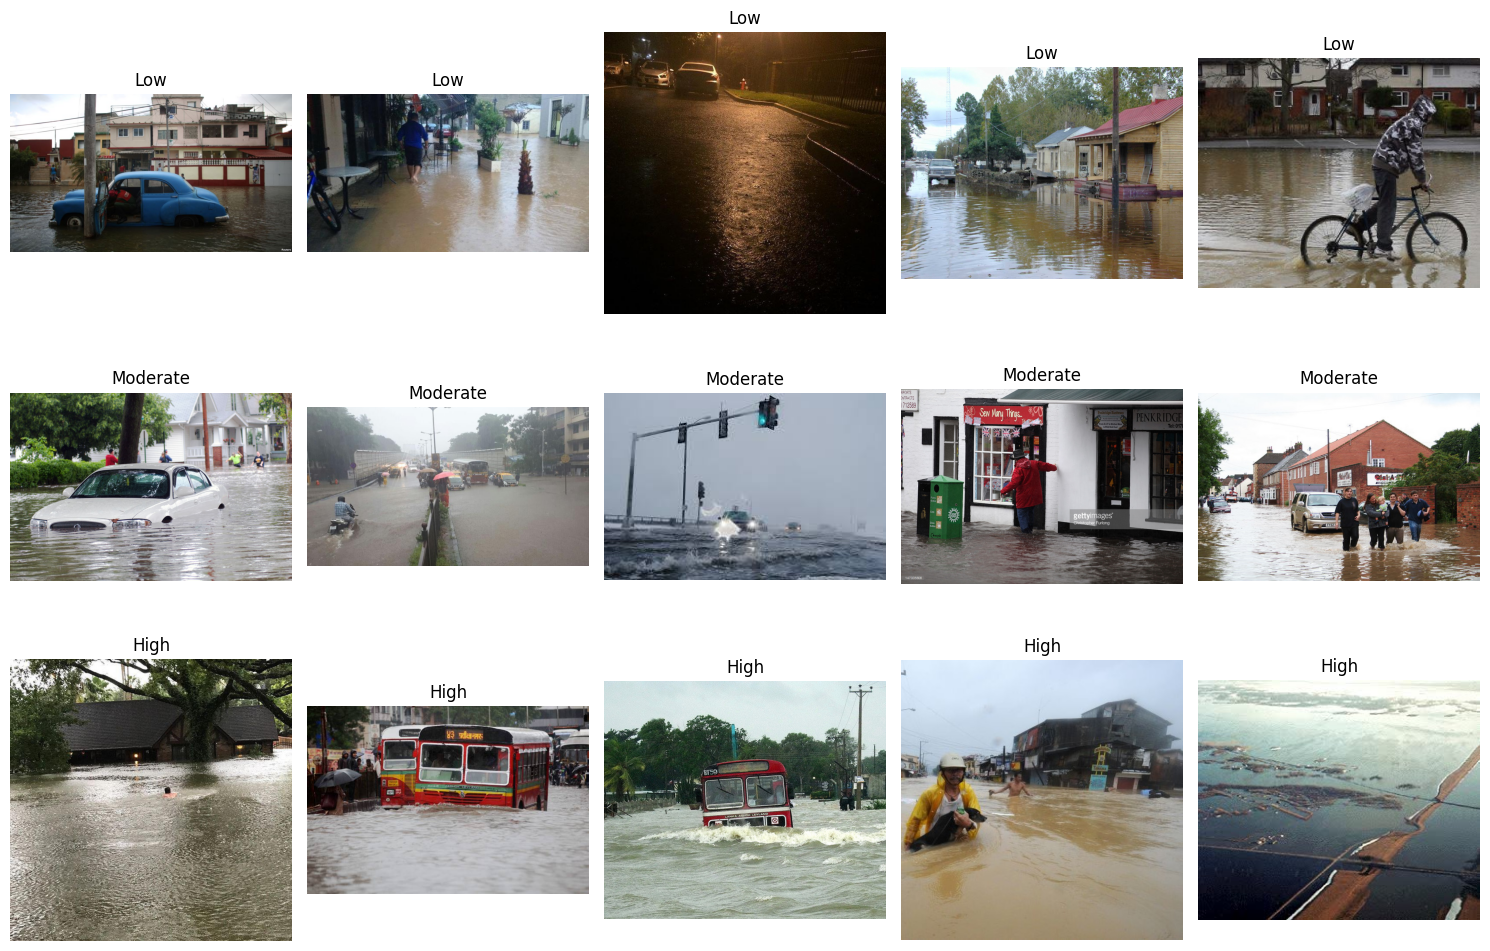

In [10]:
fig, axes = plt.subplots(3,5, figsize=(15,10))

for row, cls in enumerate(CLASSES):

    folder = os.path.join(DATASET_PATH, cls)

    images = random.sample(glob.glob(folder+"/*"),5)

    for col, img_path in enumerate(images):

        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        axes[row,col].imshow(img)
        axes[row,col].set_title(cls)
        axes[row,col].axis("off")

plt.tight_layout()
plt.show()

In [11]:
print("="*60)
print("DATASET VERIFICATION SUMMARY")
print("="*60)

print(f"Total Images      : {total}")
print(f"Duplicate Images  : {len(duplicates)}")
print(f"Corrupted Images  : {len(corrupted)}")
print(f"Invalid Formats   : {len(invalid)}")

if len(duplicates)==0 and len(corrupted)==0 and len(invalid)==0:

    print("\n✅ DATASET VERIFIED SUCCESSFULLY")

else:

    print("\n⚠ Dataset needs cleaning.")

DATASET VERIFICATION SUMMARY
Total Images      : 2890
Duplicate Images  : 45
Corrupted Images  : 0
Invalid Formats   : 0

⚠ Dataset needs cleaning.
